# Western blot quantification — diacerein vs control (horizontal fold-change panel)

Upload **either** the original ImageJ workbook (`Fig1DE_WB.xlsx`, one sheet per blot) **or** the clean `WB_Fig1DE_analysis.xlsx` (*Bands* sheet).

Each target IntDen ÷ loading-control IntDen of the same lane (α-tubulin or GAPDH on the same membrane) ÷ mean of controls. Activation ratios (caspase-1 p20/pro, GSDMD-NT/FL) are computed on the same membrane. Output: `wb_diacerein_JCI.pdf` — 4.6 × 5.0 cm, same format as the RT-qPCR Fig 1B panel (8 pt Arial-metric, geometric mean ± SEM, open circles = animals, Welch t on log₂ fold change) + stats table.

In [7]:
#@title 1 · Setup and options
import re, numpy as np, pandas as pd, matplotlib as mpl, openpyxl
import matplotlib.pyplot as plt
from scipy import stats
import subprocess, matplotlib.font_manager as fm
try:
    import google.colab
    if not any('Liberation Sans' in f.name for f in fm.fontManager.ttflist):
        subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-liberation'], check=False)
        for p in fm.findSystemFonts():
            if 'Liberation' in p: fm.fontManager.addfont(p)
except ImportError:
    pass
CM = 1 / 2.54
JCI = {'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans'], 'font.size': 8,
       'axes.labelsize': 8, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'axes.linewidth': 0.6, 'xtick.major.width': 0.6,
       'ytick.major.width': 0.6, 'xtick.major.size': 2.5, 'ytick.major.size': 0, 'xtick.direction': 'out',
       'pdf.fonttype': 42, 'ps.fonttype': 42, 'savefig.dpi': 600, 'savefig.bbox': 'standard'}
# band names used by the original sheets -> display names
BAND = {'cleaved': None, 'caspase-1': 'Pro-caspase-1', 'gsdmD': 'GSDMD (full-length)', 'alphatubulin': 'α-tubulin', 'alphatub': 'α-tubulin',
        'GAPDH': 'GAPDH', 'TLR4': 'TLR4', 'ASC.17s': 'ASC', 'IL1Bcliv': 'IL-1β'}
CLEAVED = {'M2': 'Cleaved caspase-1 (p20)', 'M10': 'Cleaved GSDMD'}   # 'cleaved' rows depend on the membrane
LOADING = {'α-tubulin', 'GAPDH'}
ORDER = ['TLR4', 'ASC', 'Pro-caspase-1', 'Cleaved caspase-1 (p20)', 'Cleaved/pro-caspase-1',
         'GSDMD (full-length)', 'Cleaved GSDMD', 'Cleaved/full-length GSDMD', 'IL-1β']
LABEL = {'TLR4': 'TLR4', 'ASC': 'ASC', 'Pro-caspase-1': 'Pro-caspase-1', 'Cleaved caspase-1 (p20)': 'Caspase-1 p20',
         'Cleaved/pro-caspase-1': 'p20/pro-casp-1', 'GSDMD (full-length)': 'GSDMD-FL', 'Cleaved GSDMD': 'GSDMD-NT',
         'Cleaved/full-length GSDMD': 'GSDMD-NT/FL', 'IL-1β': 'IL-1β'}
# panel geometry — same as RT-qPCR Fig 1B (4.6 x 5.0 cm, 8 pt, fixed margins in cm)
PANEL_W_CM, PANEL_H_CM = 4.6, 5.0
MARGIN_L, MARGIN_R, MARGIN_B, MARGIN_T = 2.05, 0.55, 1.20, 0.55   # left is wider than RT-qPCR (1.52) to fit protein names at 8 pt
X_TICKS, X_LIM = [0.25, 1, 4], (2**-3, 8)
BAR_H, BAR_FACE = 0.65, '#9cc487'
OUT = 'wb_diacerein_JCI'

In [8]:
#@title 2 · Upload and parse
try:
    from google.colab import files
    up = files.upload(); FILE = next(iter(up))
except ImportError:
    FILE = 'Fig1DE_WB.xlsx'
wb = openpyxl.load_workbook(FILE, data_only=True)

def parse_original(wb):
    rows = []
    for ws in wb:
        # header row = the one containing 'Label' and 'IntDen' (case-insensitive and trimmed)
        hr = None
        for r in range(1, ws.max_row + 1):
            row_vals = [str(c.value).strip().lower() if c.value is not None else '' for c in ws[r]]
            if any('intden' in val for val in row_vals):
                hr = r
                break
        if hr is None: continue

        heads = [str(c.value).strip() if c.value is not None else '' for c in ws[hr]]
        heads_lower = [h.lower() for h in heads]

        # Locate 'Label' and 'IntDen' columns flexibly
        li = next((i for i, h in enumerate(heads_lower) if 'label' in h), None)
        ii = next((i for i, h in enumerate(heads_lower) if 'intden' in h), None)
        if li is None or ii is None: continue

        for r in range(hr + 1, ws.max_row + 1):
            vals = [c.value for c in ws[r]]
            if len(vals) <= max(li, ii): continue
            lab, intden = vals[li], vals[ii]
            if not isinstance(intden, (int, float)): continue
            text = ' '.join(str(v) for v in vals[:li + 1] if v is not None)
            s = re.search(r'(control|diacerein) (\d+)', text, re.IGNORECASE)
            if not s: continue
            blot_match = re.search(r'(M\d+)\.', str(lab))
            blot = blot_match.group(1) if blot_match else 'Unknown'
            tag = str(vals[1]).strip() if li >= 3 else re.search(r'M\d+\.(\S+)', str(lab)).group(1)
            if tag not in BAND:
                tag_match = re.search(r'M\d+\.(\S+)', str(lab))
                tag = tag_match.group(1) if tag_match else tag
            band = CLEAVED.get(blot, 'Unknown') if tag == 'cleaved' else BAND.get(tag, tag)
            rows.append(dict(blot=blot, band=band, sample=f'{s.group(1)} {s.group(2)}',
                             group='Control' if s.group(1).lower() == 'control' else 'Diacerein', intden=float(intden)))
    return pd.DataFrame(rows)

# Fallback to parsing original sheets if 'Bands' is empty or doesn't have the required 'blot' column
b = pd.DataFrame()
if 'Bands' in wb.sheetnames:
    df_bands = pd.read_excel(FILE, sheet_name='Bands')
    if not df_bands.empty:
        df_bands.columns = [str(col).strip().lower() for col in df_bands.columns]
        if 'blot' in df_bands.columns:
            b = df_bands.rename(columns={
                'blot': 'blot',
                'band': 'band',
                'sample': 'sample',
                'group': 'group',
                'intden': 'intden'
            })

if b.empty:
    b = parse_original(wb)

print(b.groupby(['blot', 'band', 'group']).size().unstack())

Saving WB_Fig1B_analysis.xlsx to WB_Fig1B_analysis (1).xlsx
group                         Control  Diacerein
blot band                                       
M10  Cleaved GSDMD                  6          7
     GAPDH                          6          7
     GSDMD (full-length)            6          7
M2   Cleaved caspase-1 (p20)        6          8
     Pro-caspase-1                  6          8
     α-tubulin                      6          8
M4   ASC                            6          8
     GAPDH                          6          8
M5   IL-1β                          6          8
     α-tubulin                      6          8
M7   GAPDH                          6          8
     TLR4                           6          8


In [9]:
#@title 3 · Normalize, ratios, statistics
lc = b[b.band.isin(LOADING)].set_index(['blot', 'sample']).intden
t = b[~b.band.isin(LOADING)].copy()
t['ratio'] = t.intden.values / lc.loc[list(zip(t.blot, t['sample']))].values
w = t.pivot_table(index=['sample', 'group'], columns='band', values='ratio').reset_index()
for num, den, name in [('Cleaved caspase-1 (p20)', 'Pro-caspase-1', 'Cleaved/pro-caspase-1'),
                       ('Cleaved GSDMD', 'GSDMD (full-length)', 'Cleaved/full-length GSDMD')]:
    x = w[['sample', 'group', num, den]].dropna(); x['ratio'] = x[num] / x[den]; x['band'] = name
    t = pd.concat([t, x[['sample', 'group', 'band', 'ratio']]])
t['fold'] = t.ratio / t.band.map(t[t.group == 'Control'].groupby('band').ratio.mean())
t.to_csv('wb_fold_changes.csv', index=False)
rows = []
for band in ORDER:
    x = t[t.band == band]; c = np.log2(x[x.group == 'Control'].fold.values); d = np.log2(x[x.group == 'Diacerein'].fold.values)
    rows.append(dict(band=band, n_ctrl=len(c), n_diac=len(d), diac_geomean=2**d.mean(), ratio_geo=2**(d.mean() - c.mean()),
                     welch_log2_P=stats.ttest_ind(d, c, equal_var=False).pvalue,          # figure stars (RT-qPCR convention)
                     welch_fold_P=stats.ttest_ind(2**d, 2**c, equal_var=False).pvalue,
                     mwu_P=stats.mannwhitneyu(d, c).pvalue))
res = pd.DataFrame(rows).set_index('band'); display(res.round(4)); res.to_csv('wb_stats.csv')

,n_ctrl,n_diac,diac_geomean,ratio_geo,welch_log2_P,welch_fold_P,mwu_P
band,,,,,,,
TLR4,6,8,1.1466,1.1495,0.0654,0.0560,0.1419
ASC,6,8,0.8251,0.8730,0.5204,0.5138,0.7546
Pro-caspase-1,6,8,0.9011,0.9389,0.7160,0.7020,0.8518
Cleaved caspase-1 (p20),6,8,1.0009,1.0511,0.7923,0.8095,0.6620
Cleaved/pro-caspase-1,6,8,1.1003,1.1195,0.4070,0.3594,0.5728
GSDMD (full-length),6,7,1.6153,1.7306,0.0257,0.0115,0.0221
Cleaved GSDMD,6,7,0.7167,0.7585,0.1256,0.1377,0.1807
Cleaved/full-length GSDMD,6,7,0.3877,0.4383,0.0135,0.0326,0.0012
IL-1β,6,8,0.4074,0.4407,0.0025,0.0357,0.0007


Panel size: 4.6 x 5.0 cm


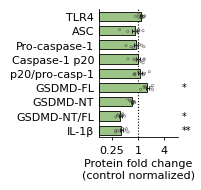

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
#@title 4 · Figure — 4.6 x 5.0 cm, RT-qPCR Fig 1B format (geometric mean ± SEM, open circles, Welch on log2)
star = lambda p: '****' if p < 1e-4 else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else ''
with mpl.rc_context(JCI):
    fig = plt.figure(figsize=(PANEL_W_CM * CM, PANEL_H_CM * CM))
    ax = fig.add_axes([MARGIN_L / PANEL_W_CM, MARGIN_B / PANEL_H_CM,
                       1 - (MARGIN_L + MARGIN_R) / PANEL_W_CM, 1 - (MARGIN_B + MARGIN_T) / PANEL_H_CM])
    rng = np.random.default_rng(7)
    for i, band in enumerate(ORDER):
        y = len(ORDER) - 1 - i
        d = np.log2(t[(t.band == band) & (t.group == 'Diacerein')].fold.values)
        m = 2 ** d.mean(); se = d.std(ddof=1) / np.sqrt(len(d))
        ax.barh(y, m - X_LIM[0], left=X_LIM[0], height=BAR_H, facecolor=BAR_FACE, edgecolor='black', linewidth=0.6, zorder=2)
        ax.errorbar(m, y, xerr=[[m - 2**(d.mean() - se)], [2**(d.mean() + se) - m]], color='k', capsize=1.5,
                    elinewidth=0.6, capthick=0.6, fmt='none', zorder=3)
        ax.scatter(2**d, rng.normal(y, BAR_H * 0.16, len(d)), s=2.8, facecolor='none', edgecolor='0.3', linewidth=0.35, zorder=4)
        ax.text(1.05, y, star(res.loc[band, 'welch_log2_P']), transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=7)
    ax.axvline(1.0, ls=':', color='k', lw=0.8, zorder=1)
    ax.set_xscale('log', base=2); ax.set_xticks(X_TICKS); ax.set_xticklabels([f'{v:g}' for v in X_TICKS])
    ax.xaxis.set_minor_locator(mpl.ticker.NullLocator()); ax.set_xlim(*X_LIM)
    ax.set_yticks(range(len(ORDER))); ax.set_yticklabels([LABEL[b_] for b_ in ORDER][::-1]); ax.set_ylim(-0.5, len(ORDER) - 0.5)
    ax.set_xlabel('Protein fold change\n(control normalized)', labelpad=2)
    ax.spines[['top', 'right']].set_visible(False)
    fig.savefig(OUT + '.pdf'); fig.savefig(OUT + '.png', dpi=600)
    fig.savefig(OUT + '.tiff', dpi=600, pil_kwargs={'compression': 'tiff_lzw'})
w_, h_ = fig.get_size_inches(); print(f'Panel size: {w_/CM:.1f} x {h_/CM:.1f} cm')
plt.show()
try:
    from google.colab import files
    files.download(OUT + '.pdf'); files.download('wb_fold_changes.csv'); files.download('wb_stats.csv')
except ImportError:
    pass